# Prior Sensitivity Analysis

In [ ]:
# =============================================================================
# 1. Setup & Loading Data
# =============================================================================
import gc
import json
from os import chdir, path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import torch

torch.set_default_device('cuda' if torch.cuda.is_available() else 'cpu')

homedir = path.expanduser("~")
reppath = path.join(homedir,"plandepth_aud_tud") # TODO: change to your individual path to the repository
datadir = path.join(reppath, "data")
fitdir  = path.join(datadir, "PosteriorSamples", "2025-02-03_LPP_and_probDiscounting")
prior_sensitivity_dir = path.join(datadir, "PosteriorSamples", "2026_10_20_LPP_and_probDiscounting_PRIOR_SENSITIVITY")
chdir(reppath)

from helpers import load_and_format_SAT_data
from local_agents import BackInduction_LPP_and_probDiscounting
from inference import Inferrer

filenames = ["space_adventure_pd-results.json", "space_adventure_pd_inv-results.json"]
exclusion_ids = pd.read_csv(path.join(datadir, "exclusion_ids.csv"), dtype={"ID": object}).ID.to_list()
df_matched_ids = pd.read_csv(path.join(datadir, "matched_ids.csv"), dtype={"ID": object, "matched_ID": object})

# Configure 6 distinct groups and their file suffixes
group_config = {
    "AUD": {
        "dir": path.join(datadir, "AUD_only"),
        "suffix": "aud",
        "is_patient": True
    },
    "HC_match_AUD": {
        "dir": path.join(datadir, "HC"),
        "suffix": "hc_m_a",
        "is_patient": False,
        "match_ref": "AUD"
    },
    "TUD": {
        "dir": path.join(datadir, "TUD_only"),
        "suffix": "tud",
        "is_patient": True
    },
    "HC_match_TUD": {
        "dir": path.join(datadir, "HC"),
        "suffix": "hc_m_t",
        "is_patient": False,
        "match_ref": "TUD"
    },
    "AUD_and_TUD": {
        "dir": path.join(datadir, "AUD_and_TUD"),
        "suffix": "aud_tud",
        "is_patient": True
    },
    "HC_match_AUD_and_TUD": {
        "dir": path.join(datadir, "HC"),
        "suffix": "hc_m_at",
        "is_patient": False,
        "match_ref": "AUD_and_TUD"
    }
}

group_data = {}
all_results = []
depth_weights = np.array([1, 2, 3])

print("Lade Verhaltenstexte und Baseline-Fits (prior_scale = 1.0)...")

for g_label, cfg in group_config.items():
    # A) Get Subject-IDs
    if cfg["is_patient"]:
        inc_ids = []
    else:
        # filter Matched HCs for respective patient group
        patient_ids = group_data[cfg["match_ref"]]["ids"]
        inc_ids = df_matched_ids[df_matched_ids['ID'].isin(patient_ids)]['matched_ID'].tolist()

    # B) Load behavioral data
    stim, mask, resp, _, _, _, ids, _, _ = load_and_format_SAT_data(
        cfg["dir"], filenames, discard_training_blocks=False, exclusion_ids=exclusion_ids, inclusion_ids=inc_ids
    )
    group_data[g_label] = {"stimuli": stim, "mask": mask, "responses": resp, "ids": ids}

    # C) Load Baseline Fit (prior_scale = 1.0)
    pars_file = path.join(fitdir, f"pars_post_samples_{cfg['suffix']}.csv")
    npz_file = path.join(fitdir, f"plandepth_stats_{cfg['suffix']}.npz")

    # Parameters (.csv)
    pars_df_1 = pd.read_csv(pars_file, index_col=0, dtype={"ID": str})
    subj_means_1 = pars_df_1.groupby(["ID", "parameter"])["value"].mean().unstack("parameter").reset_index()

    # Planning Depth (.npz)
    m_prob_1 = np.load(npz_file, allow_pickle=True)['arr_1']
    mean_depth_per_subj = (m_prob_1[0] * depth_weights).sum(axis=-1).mean(axis=0)
    
    depth_df_1 = pd.DataFrame({"ID": ids, r"$d$": mean_depth_per_subj})
    subj_means_1 = subj_means_1.merge(depth_df_1, on="ID")

    # Convert to target DataFrame-Format and append to all_results
    df_melt_1 = subj_means_1.melt(id_vars=["ID"], var_name="parameter", value_name="value")
    df_melt_1["group"] = g_label
    df_melt_1["prior_scale"] = "1.0"
    all_results.append(df_melt_1)

Lade Verhaltenstexte und Baseline-Fits (prior_scale = 1.0)...


In [ ]:
# =============================================================================
# 2. Sensitivity Inference Wrapper
# =============================================================================

from pyroapi import infer


def get_posterior_stats(post_marg, mini_blocks=140):
    n_samples, runs, max_trials = post_marg['d_0_0'].shape
    post_depth = {0: np.zeros((n_samples, mini_blocks, runs, max_trials)),
                  1: np.zeros((n_samples, mini_blocks, runs, max_trials))}
    for pm in post_marg:
        b, t = np.array(pm.split('_')[1:]).astype(int)
        if t in post_depth:
            post_depth[t][:, b] = post_marg[pm]

    # Mean probabilities for each planning depth
    m_prob = [post_depth[c].mean(0) for c in range(2)]

    # Planning Depth Exceedance Count
    exc_count = [np.array([np.sum(post_depth[t].argmax(-1) == i, 0) for i in range(3)]) for t in range(2)]
    
    return post_depth, m_prob, exc_count


def run_sensitivity_inference(stimuli, mask, responses, subject_ids, prior_scale, num_iterations=1000, num_particles=100):
    runs, blocks, max_trials = responses.shape
    confs = stimuli["configs"]
    
    agent = BackInduction_LPP_and_probDiscounting(
        confs,
        runs=runs,
        mini_blocks=blocks,
        trials=max_trials,
        costs=torch.tensor([0, 0]),
        planning_depth=3,
    )

    infer = Inferrer(agent, stimuli, responses, mask, prior_scale=prior_scale)
    infer.fit(num_iterations=num_iterations, num_particles=num_particles)
    
    # Extract Posterior Samples
    labels = [r"$\tilde{\beta}$", r"$\theta$", r"${k}$"]
    pars_df, _, _ = infer.sample_from_posterior(labels)

    # Transformations
    pars_df[r"$\beta$"] = torch.from_numpy(pars_df[r"$\tilde{\beta}$"].values).exp().numpy()
    pars_df[r"$k$"] = 30.0 * torch.from_numpy(pars_df[r"${k}$"].values).sigmoid().numpy()
    pars_df.drop([r"$\tilde{\beta}$"], axis=1, inplace=True, errors="ignore")
    
    # Mapping of IDs and adding the model
    subject_indices = pars_df.subject.values - 1
    pars_df["ID"] = np.array(subject_ids)[subject_indices]
    
    # Calc mean parameter values per subject
    subj_means = pars_df.groupby("ID")[[r"$\beta$", r"$\theta$", r"$k$"]].mean().reset_index()
    
    # Extract Planning Depth probabilities (m_prob)
    post_marg = infer.sample_posterior_marginal(n_samples=100)
    _, m_prob, _ = get_posterior_stats(post_marg, mini_blocks=blocks)
    
    # Calc expected mean planning depth (weighted average of depths 1, 2, 3)
    depth_weights = np.array([1, 2, 3])
    mean_depth_per_subj = (m_prob[0] * depth_weights).sum(axis=-1).mean(axis=0)  # Shape: (runs,)
    
    depth_df = pd.DataFrame({"ID": subject_ids, r"$d$": mean_depth_per_subj})
    subj_means = subj_means.merge(depth_df, on="ID")
    
    return subj_means


In [ ]:
# =============================================================================
# 3. Main Loop: Prior Scales and Groups
# =============================================================================
prior_scales = [0.5, 2.0]
if "all_results" not in locals():
    all_results = []

print("Starte Prior Sensitivity Analysis...")
for scale in prior_scales:
    for g_label, data in group_data.items():
        print(f"Fitting Group: {g_label} | Prior Scale: {scale}")
        
        df_means = run_sensitivity_inference(
            data["stimuli"], 
            data["mask"], 
            data["responses"], 
            data["ids"], 
            prior_scale=scale
        )
        
        # Melt dataframe for easier plotting with Seaborn
        df_melt = df_means.melt(id_vars=["ID"], var_name="parameter", value_name="value")
        df_melt["group"] = g_label
        df_melt["prior_scale"] = str(scale)
        
        all_results.append(df_melt)
        
        # RAM Cleanup after each inference to avoid memory issues
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            gc.collect()

# Final results DataFrame
results_df = pd.concat(all_results, ignore_index=True)
results_df.to_csv(path.join(prior_sensitivity_dir, "prior_sensitivity_results.csv"), index=False)

Starte Prior Sensitivity Analysis...
Fitting Group: AUD | Prior Scale: 0.5
Mean ELBO 7995.89:  12%|██████████████████████▌                                                                                                                                                                           | 116/1000 [05:03<39:30,  2.68s/it]

  0%|                                                                                                                                                                                                                               | 0/1000 [00:00<?, ?it/s]

Mean ELBO 8019.14:   7%|█████████████▊                                                                                                                                                                                     | 71/1000 [03:04<40:17,  2.60s/it]

In [ ]:
# # load pre-existing results of fits
# results_df = pd.read_csv(path.join(datadir, "prior_sensitivity_results.csv"), dtype={"ID": str, "parameter": str, "value": float, "group": str, "prior_scale": str})

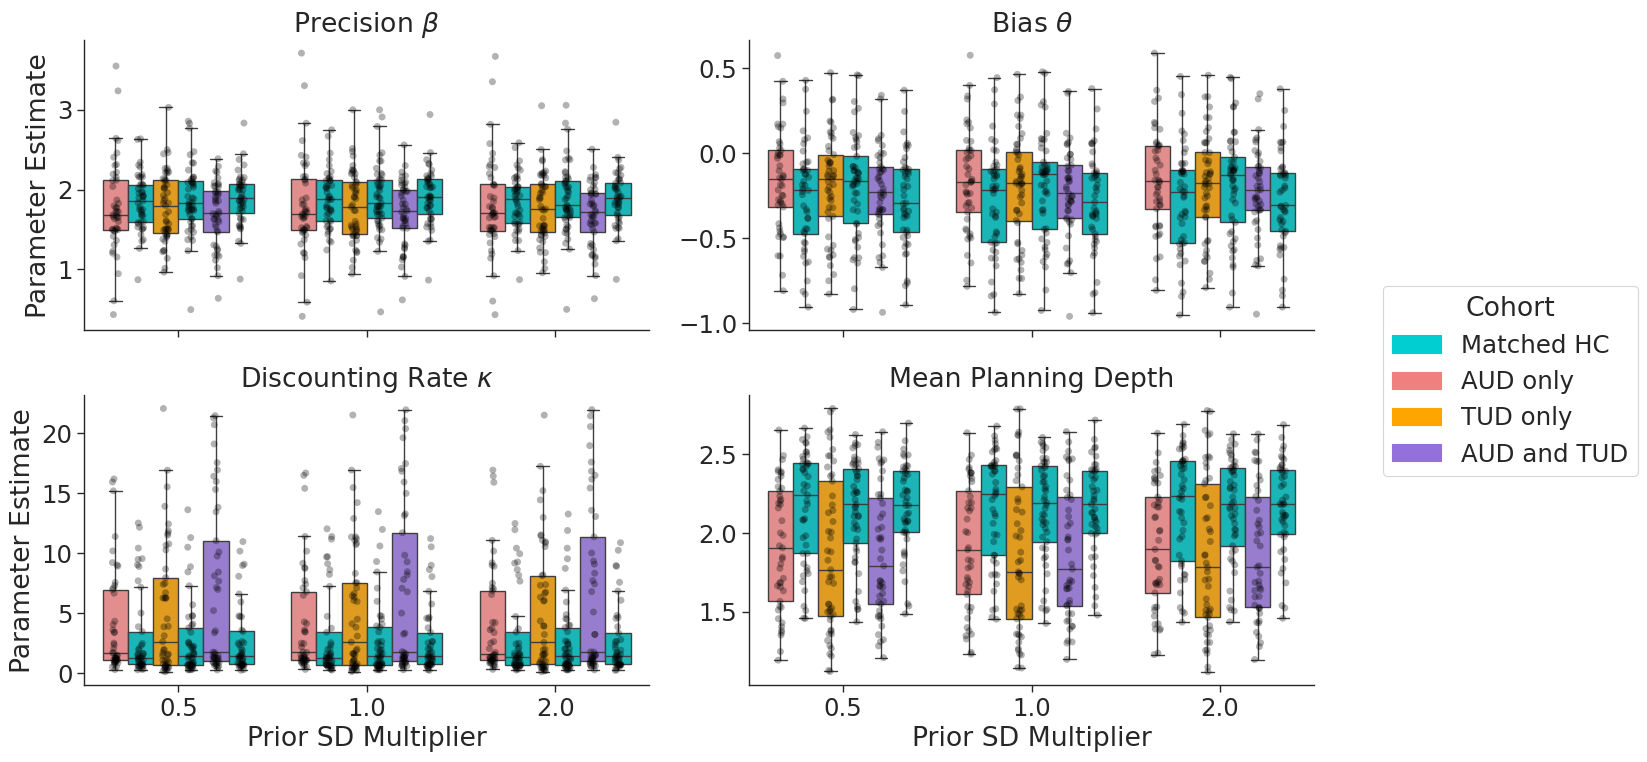

In [ ]:
# =============================================================================
# 4. Visualization: Boxplot + Stripplot (2x2 Grid & Custom Colors)
# =============================================================================
import matplotlib.patches as mpatches

sns.set_theme(style="ticks", context="paper", font_scale=2)

alpha_scatter = 0.3 # Globale parameter for transparency of the scatter points
group_palette = ['darkturquoise', 'lightcoral', 'orange', 'mediumpurple']

# Mapping of 6 groups to the 4 colors in the palette
custom_palette = {
    "HC_match_AUD": group_palette[0],
    "HC_match_TUD": group_palette[0],
    "HC_match_AUD_and_TUD": group_palette[0],
    "AUD": group_palette[1],
    "TUD": group_palette[2],
    "AUD_and_TUD": group_palette[3]
}

group_order = [
    "AUD", "HC_match_AUD",
    "TUD", "HC_match_TUD",
    "AUD_and_TUD", "HC_match_AUD_and_TUD"
]
scale_order = ["0.5", "1.0", "2.0"]

black_palette = {g: "black" for g in group_order}

g = sns.catplot(
    data=results_df,
    x="prior_scale",
    y="value",
    hue="group",
    col="parameter",
    col_wrap=2,               # get 2x2 grid with the 4 parameters
    kind="box",
    sharey=False,
    palette=custom_palette,
    order=scale_order,
    hue_order=group_order,
    height=4,
    aspect=1.2,
    showfliers=False
)

g.map_dataframe(
    sns.stripplot,
    x="prior_scale",
    y="value",
    hue="group",
    dodge=True,
    alpha=alpha_scatter,
    palette=black_palette,
    order=scale_order,
    hue_order=group_order
)

# Labels and Titles
g.set_axis_labels("Prior SD Multiplier", "Parameter Estimate")
#g.set_titles("{col_name}")
#g.despine(trim=True)

custom_titles = [r'Precision $\beta$', r'Bias $\theta$', r'Discounting Rate $\kappa$', 'Mean Planning Depth']
for ax, title in zip(g.axes.flat, custom_titles):
    ax.set_title(title)

# Set legend
if g._legend:
    g._legend.remove()

legend_labels = ['Matched HC', 'AUD only', 'TUD only', 'AUD and TUD']
legend_patches = [mpatches.Patch(color=c, label=l) for c, l in zip(group_palette, legend_labels)]

g.figure.legend(
    handles=legend_patches, 
    title="Cohort", 
    bbox_to_anchor=(1.02, 0.5), 
    loc='center left'
)

plt.tight_layout()
plt.savefig(path.join(prior_sensitivity_dir, "prior_sensitivity_main_plot.png"), bbox_inches="tight")
plt.show()

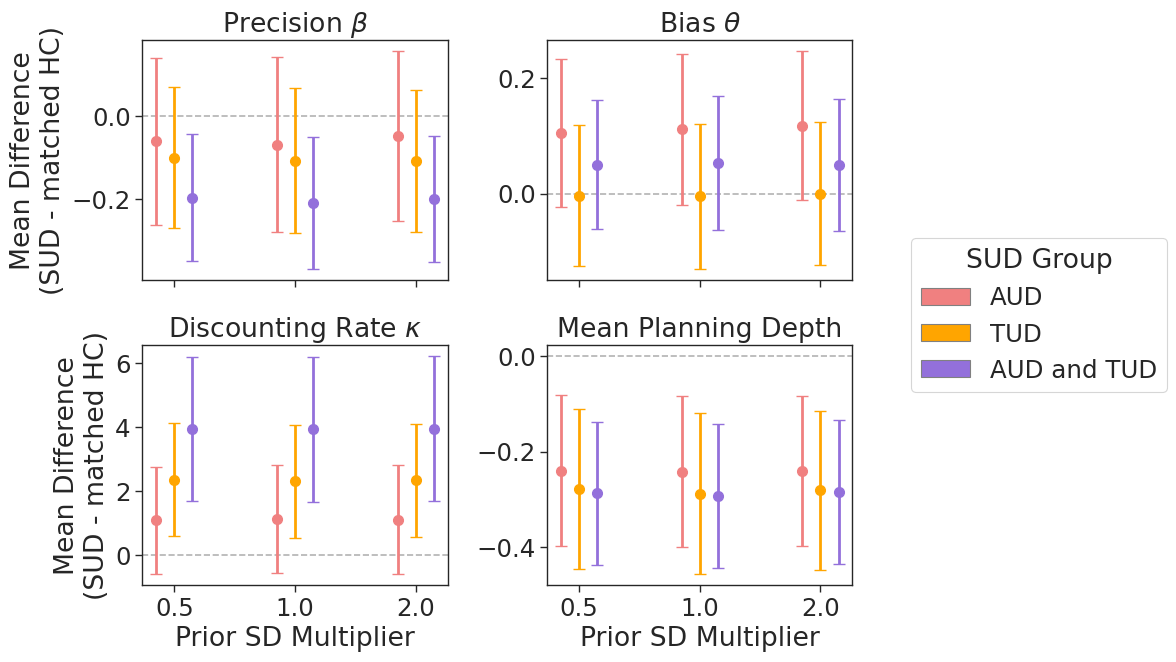

In [39]:
# =============================================================================
# 5. Data Wrangling: 2 independent sample mean differences (Welch-Approximation)
# =============================================================================
import scipy.stats as stats

patient_groups = ["AUD", "TUD", "AUD_and_TUD"]
prior_scales = ["0.5", "1.0", "2.0"]
params = [r"$\beta$", r"$\theta$", r"$k$", r"$d$"] # order of parameters for plotting

diff_records = []

for p_group in patient_groups:
    hc_group = f"HC_match_{p_group}"
    
    for param in params:
        for scale in prior_scales:
            # Values of the patients and controls for this parameter and this prior scale
            vals_p = results_df[(results_df["group"] == p_group) & 
                                (results_df["parameter"] == param) & 
                                (results_df["prior_scale"] == scale)]["value"].values
            
            vals_hc = results_df[(results_df["group"] == hc_group) & 
                                 (results_df["parameter"] == param) & 
                                 (results_df["prior_scale"] == scale)]["value"].values
            
            n_p, n_hc = len(vals_p), len(vals_hc)
            
            if n_p == 0 or n_hc == 0:
                continue
            
            # Means and variances (Bessel-correction ddof=1 for sample variance)
            mean_p, mean_hc = np.mean(vals_p), np.mean(vals_hc)
            var_p, var_hc = np.var(vals_p, ddof=1), np.var(vals_hc, ddof=1)
            
            # Difference and Standard Error of the Difference (Independent Samples / Welch)
            mean_diff = mean_p - mean_hc
            se_diff = np.sqrt((var_p / n_p) + (var_hc / n_hc))
            
            # Degrees of Freedom (Welch-Satterthwaite Equation)
            df_num = (var_p / n_p + var_hc / n_hc)**2
            df_den = ((var_p / n_p)**2) / (n_p - 1) + ((var_hc / n_hc)**2) / (n_hc - 1)
            df = df_num / df_den
            
            # 95% Confidence Interval using t-distribution critical value
            t_crit = stats.t.ppf(0.975, df)
            margin_error = t_crit * se_diff
            
            diff_records.append({
                "group": p_group,
                "parameter": param,
                "prior_scale": scale,
                "mean_diff": mean_diff,
                "margin_error": margin_error
            })

df_diff = pd.DataFrame(diff_records)


# =============================================================================
# 5. Visualization: 95% CI Pointplot with 2x2 Grid
# =============================================================================
import matplotlib.patches as mpatches

sns.set_theme(style="ticks", context="paper", font_scale=2)

custom_titles = [r'Precision $\beta$', r'Bias $\theta$', r'Discounting Rate $\kappa$', 'Mean Planning Depth']
custom_palette = {"AUD": "lightcoral", "TUD": "orange", "AUD_and_TUD": "mediumpurple"}

# Mapping of x-axes values and dodging offsets
x_map = {"0.5": 0, "1.0": 1, "2.0": 2}
dodge_map = {"AUD": -0.15, "TUD": 0.0, "AUD_and_TUD": 0.15}

fig, axes = plt.subplots(2, 2, figsize=(9, 7))
axes = axes.flatten()

for i, param in enumerate(params):
    ax = axes[i]
    
    ax.axhline(0, ls='--', color='gray', alpha=0.6, zorder=0)
    ax.set_title(custom_titles[i])
    
    # Plot per patient group
    for p_group in patient_groups:
        sub_df = df_diff[(df_diff["parameter"] == param) & (df_diff["group"] == p_group)]
        
        # Calc x-positions with dodge-offsets
        x_vals = [x_map[s] + dodge_map[p_group] for s in sub_df["prior_scale"]]
        y_vals = sub_df["mean_diff"].values
        y_err = sub_df["margin_error"].values

        ax.errorbar(
            x=x_vals, 
            y=y_vals, 
            yerr=y_err, 
            fmt='o',            
            color=custom_palette[p_group],
            capsize=4,
            elinewidth=2,
            markersize=7, 
            zorder=3
        )
    
    # set ticks and labels
    ax.set_xticks([0, 1, 2], labels=["", "", ""])
    #ax.set_xticklabels(["0.5", "1.0", "2.0"])
    #ax.set_xlabel("Prior SD Multiplier")
    
    if i >= 2:
        ax.set_xticks([0, 1, 2], labels=["0.5", "1.0", "2.0"])
        ax.set_xlabel("Prior SD Multiplier")
    if i % 2 == 0:
        ax.set_ylabel("Mean Difference\n(SUD - matched HC)")

#sns.despine(trim=True, fig=fig) # minimalist design

# Craft legend
legend_elements = [
    mpatches.Patch(facecolor='lightcoral', edgecolor='gray', label='AUD'),
    mpatches.Patch(facecolor='orange', edgecolor='gray', label='TUD'),
    mpatches.Patch(facecolor='mediumpurple', edgecolor='gray', label='AUD and TUD')
]

fig.legend(handles=legend_elements, title="SUD Group", bbox_to_anchor=(1.02, 0.65), loc='upper left')

plt.tight_layout()
plt.savefig(path.join(prior_sensitivity_dir, "prior_sensitivity_ci_plot.png"), bbox_inches="tight")
plt.show()